# NLP Assignment: End-to-End NLP Pipeline for Banking Chatbot Intent Recognition

Dataset: Banking77  
Use case: Customer-service banking chatbot  
Main tasks:
1. Preprocessing and exploratory analysis
2. Classical intent classification
3. Word2Vec semantic retrieval
4. DistilBERT fine-tuning
5. Responsible conversational AI discussion

### Install Libraries

In [1]:
!pip install -q datasets transformers evaluate accelerate gensim spacy nltk scikit-learn seaborn wordcloud
!python -m spacy download en_core_web_sm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 42.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 104.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [3]:
!pip install -U datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 529.0/529.0 kB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 23.1 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 18.1.0
    Uninstalling pyarrow-18.1.0:
      Successfully uninstalled pyarrow-18.1.0
  Attempting uninstall: datasets
    Found existing installation: datasets 2.19.2
    Uninstalling datasets-2.19.2:
      Successfully uninstalled datasets-2.19.2


### Import Libraries

In [13]:
# Import core libraries for text processing, timing, randomness, and numerical analysis.
import re
import time
import random
import numpy as np
import pandas as pd

# Import visualization libraries for exploratory data analysis and model evaluation.
import matplotlib.pyplot as plt
import seaborn as sns

# Import NLP libraries for tokenization, lemmatization, and linguistic preprocessing.
import nltk
import spacy

# Load datasets and support frequency-based text analysis.
from datasets import load_dataset
from collections import Counter

# Import NLTK tools for common text preprocessing steps.
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Import machine learning utilities for splitting data, feature extraction, modelling, and evaluation.
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

# Import Word2Vec and dimensionality reduction methods for word embedding analysis.
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Import PyTorch and Transformer components for deep learning-based text classification.
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
    pipeline
)

# Download required NLTK resources for tokenization, stopword removal, and lemmatization.
nltk.download("punkt")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

# Load the small English spaCy model for linguistic processing.
nlp = spacy.load("en_core_web_sm")

# Set a fixed random seed to support reproducibility across experiments.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


### Load Dataset

In [14]:
from datasets import load_dataset

dataset = load_dataset("mteb/banking77")

train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

train_df.head()

,text,label,label_text
0,I am still waiting on my card?,11,card_arrival
1,What can I do if my card still hasn't arrived ...,11,card_arrival
2,I have been waiting over a week. Is the card s...,11,card_arrival
3,Can I track my card while it is in the process...,11,card_arrival
4,"How do I know if I will get my card, or if it ...",11,card_arrival


### Inspect Dataset

In [15]:
print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("\nColumns:", train_df.columns.tolist())
print("\nExample utterances:")
display(train_df.sample(10, random_state=SEED))

Training shape: (9993, 3)
Test shape: (3076, 3)

Columns: ['text', 'label', 'label_text']

Example utterances:


,text,label,label_text
3123,What are the limits to where my card will be a...,10,card_acceptance
1441,I would like to change currency,33,exchange_via_app
6282,I have lost my credit card in the ATM!,18,card_swallowed
39,My card still hasn't been delivered,11,card_arrival
4094,Can you deliver the PIN separately?,38,get_physical_card
1599,I am 16 and just started working at McDonalds ...,1,age_limit
4381,Whats the maximum number of disposable cards t...,29,disposable_card_limits
7510,Been trying to transfer money this morning but...,35,failed_transfer
500,Why is the exchange rate different from what I...,17,card_payment_wrong_exchange_rate
4553,How do I withdraw money?,3,atm_support


### Add Label Names

In [16]:
# Create a mapping between numerical labels and their corresponding intent names.
label_map = (
    train_df[["label", "label_text"]]
    .drop_duplicates()
    .sort_values("label")
    .reset_index(drop=True)
)

# Store all intent names in a list for later reference and model interpretation.
label_names = label_map["label_text"].tolist()

# Create a more descriptive target column using intent names instead of numeric labels.
train_df["intent"] = train_df["label_text"]
test_df["intent"] = test_df["label_text"]

# Display the first few label-to-intent mappings.
display(label_map.head(10))

# Preview the training dataset after adding the intent column.
display(train_df.head())

# Report the size of the training dataset.
print("Number of training examples:", len(train_df))

# Report the size of the test dataset.
print("Number of test examples:", len(test_df))

# Show the total number of unique intent categories.
print("Number of intents:", train_df["intent"].nunique())

# Display the first ten intent labels for inspection.
print("First 10 intent names:", label_names[:10])

,label,label_text
0,0,activate_my_card
1,1,age_limit
2,2,apple_pay_or_google_pay
3,3,atm_support
4,4,automatic_top_up
5,5,balance_not_updated_after_bank_transfer
6,6,balance_not_updated_after_cheque_or_cash_deposit
7,7,beneficiary_not_allowed
8,8,cancel_transfer
9,9,card_about_to_expire


,text,label,label_text,intent
0,I am still waiting on my card?,11,card_arrival,card_arrival
1,What can I do if my card still hasn't arrived ...,11,card_arrival,card_arrival
2,I have been waiting over a week. Is the card s...,11,card_arrival,card_arrival
3,Can I track my card while it is in the process...,11,card_arrival,card_arrival
4,"How do I know if I will get my card, or if it ...",11,card_arrival,card_arrival


Number of training examples: 9993
Number of test examples: 3076
Number of intents: 77
First 10 intent names: ['activate_my_card', 'age_limit', 'apple_pay_or_google_pay', 'atm_support', 'automatic_top_up', 'balance_not_updated_after_bank_transfer', 'balance_not_updated_after_cheque_or_cash_deposit', 'beneficiary_not_allowed', 'cancel_transfer', 'card_about_to_expire']


## Task 1 — Preprocessing and Exploratory Analysis

This task investigates the linguistic characteristics of the Banking77 dataset through preprocessing and exploratory analysis. NLTK and spaCy are used for tokenisation, lemmatisation, stopword removal, and named entity recognition to understand how preprocessing decisions influence intent recognition in chatbot systems.

### Intent Distribution

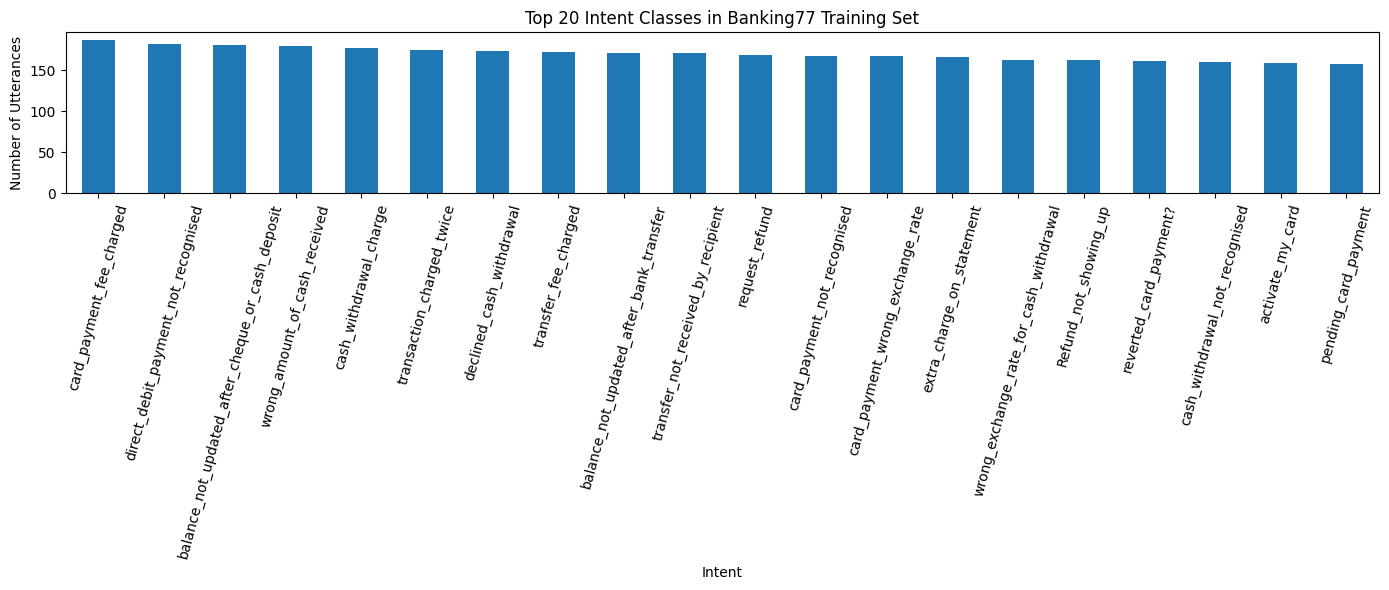

,Count,count
0,card_payment_fee_charged,187
1,direct_debit_payment_not_recognised,182
2,balance_not_updated_after_cheque_or_cash_deposit,181
3,wrong_amount_of_cash_received,180
4,cash_withdrawal_charge,177
5,transaction_charged_twice,175
6,declined_cash_withdrawal,173
7,transfer_fee_charged,172
8,balance_not_updated_after_bank_transfer,171
9,transfer_not_received_by_recipient,171


In [17]:
# Calculate the frequency of each intent class in the training dataset.
intent_counts = train_df["intent"].value_counts()

# Visualize the distribution of the 20 most frequent intent categories.
plt.figure(figsize=(14, 6))
intent_counts.head(20).plot(kind="bar")

# Add descriptive labels and title to improve interpretability.
plt.title("Top 20 Intent Classes in Banking77 Training Set")
plt.xlabel("Intent")
plt.ylabel("Number of Utterances")

# Rotate x-axis labels for better readability.
plt.xticks(rotation=75)

# Adjust layout to prevent label overlap.
plt.tight_layout()

# Display the bar chart.
plt.show()

# Present the top 20 intent frequencies in tabular form for easier inspection.
display(
    intent_counts.head(20).reset_index().rename(
        columns={"index": "Intent", "intent": "Count"}
    )
)

### Basic Text Statistics

,text_length,word_count
count,9993.000000,9993.000000
mean,59.501351,11.955369
std,40.873384,7.891187
min,13.000000,3.000000
25%,36.000000,7.000000
50%,47.000000,10.000000
75%,64.000000,13.000000
max,433.000000,79.000000


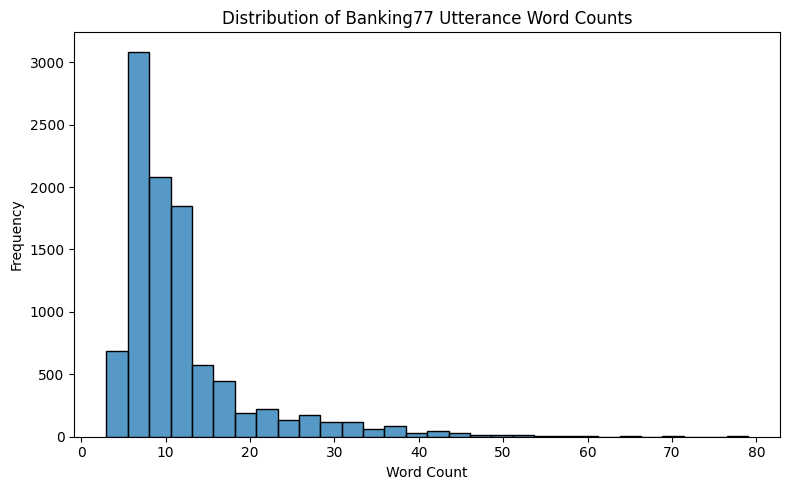

In [18]:
# Compute the character length of each utterance to examine text size variability.
train_df["text_length"] = train_df["text"].apply(len)

# Compute the number of words in each utterance for descriptive analysis.
train_df["word_count"] = train_df["text"].apply(lambda x: len(x.split()))

# Generate summary statistics for text length and word count features.
display(train_df[["text_length", "word_count"]].describe())

# Visualize the distribution of utterance lengths measured by word count.
plt.figure(figsize=(8, 5))
sns.histplot(train_df["word_count"], bins=30)

# Add informative labels and title to the histogram.
plt.title("Distribution of Banking77 Utterance Word Counts")
plt.xlabel("Word Count")
plt.ylabel("Frequency")

# Adjust spacing to ensure a clear and readable figure.
plt.tight_layout()

# Display the histogram.
plt.show()

### NLTK Preprocessing Function

In [19]:
# Download the required NLTK resources for tokenization, stopword filtering, and lemmatization.
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

# Initialize the English stopword list and WordNet lemmatizer.
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

# Define a preprocessing function to clean and normalize textual data.
def preprocess_nltk(text, remove_stopwords=True):

    # Convert text to lowercase to ensure case-insensitive processing.
    text = str(text).lower()

    # Remove numbers, punctuation, and special characters.
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    # Tokenize the cleaned text into individual words.
    tokens = word_tokenize(text)

    # Optionally remove common stopwords that carry limited semantic information.
    if remove_stopwords:
        tokens = [token for token in tokens if token not in stop_words]

    # Apply lemmatization to reduce words to their base forms.
    lemmas = [lemmatizer.lemmatize(token) for token in tokens]

    # Return the processed tokens.
    return lemmas

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


### spaCy Preprocessing Function

In [20]:
# Define a spaCy-based preprocessing function for linguistic text normalization.
def preprocess_spacy(text, remove_stopwords=True):

    # Process the input text using the spaCy language model.
    doc = nlp(str(text).lower())
    tokens = []

    # Iterate through each token in the processed document.
    for token in doc:

        # Retain only alphabetic tokens and discard punctuation, numbers, and symbols.
        if token.is_alpha:

            # Optionally remove stopwords to reduce non-informative terms.
            if remove_stopwords and token.is_stop:
                continue

            # Store the lemmatized form of each token.
            tokens.append(token.lemma_)

    # Return the cleaned and normalized token list.
    return tokens

### Compare NLTK and spaCy Outputs

In [21]:
# Select a sample utterance from the dataset for preprocessing comparison.
sample_text = train_df["text"].iloc[10]

# Display the original text before preprocessing.
print("Original text:")
print(sample_text)

# Apply the NLTK preprocessing pipeline and display the resulting tokens.
print("\nNLTK output:")
print(preprocess_nltk(sample_text))

# Apply the spaCy preprocessing pipeline and display the resulting tokens.
print("\nspaCy output:")
print(preprocess_spacy(sample_text))

Original text:
Why has my new card still not come?

NLTK output:
['new', 'card', 'still', 'come']

spaCy output:
['new', 'card', 'come']


### NLTK vs spaCy Comparison Table

In [22]:
# Randomly sample 200 utterances to compare the outputs of NLTK and spaCy preprocessing.
sample_texts = train_df["text"].sample(200, random_state=SEED)

comparison_rows = []

# Process each sampled utterance using both preprocessing pipelines.
for text in sample_texts:

    nltk_tokens = preprocess_nltk(text)
    spacy_tokens = preprocess_spacy(text)

    # Store token statistics and processed outputs for comparison.
    comparison_rows.append({
        "original_text": text,
        "nltk_token_count": len(nltk_tokens),
        "spacy_token_count": len(spacy_tokens),
        "nltk_tokens": nltk_tokens,
        "spacy_tokens": spacy_tokens
    })

# Convert the collected results into a DataFrame for analysis.
comparison_df = pd.DataFrame(comparison_rows)

# Summarize the average token counts and vocabulary sizes produced by each method.
summary_table = pd.DataFrame({
    "Method": ["NLTK", "spaCy"],
    "Average Token Count": [
        comparison_df["nltk_token_count"].mean(),
        comparison_df["spacy_token_count"].mean()
    ],
    "Vocabulary Size": [
        len(set(token for tokens in comparison_df["nltk_tokens"] for token in tokens)),
        len(set(token for tokens in comparison_df["spacy_tokens"] for token in tokens))
    ]
})

# Display the comparative summary statistics.
display(summary_table)

# Display a sample of the detailed comparison results.
display(comparison_df.head())

,Method,Average Token Count,Vocabulary Size
0,NLTK,5.660,393
1,spaCy,4.525,291


,original_text,nltk_token_count,spacy_token_count,nltk_tokens,spacy_tokens
0,What are the limits to where my card will be a...,3,3,"[limit, card, accepted]","[limit, card, accept]"
1,I would like to change currency,4,3,"[would, like, change, currency]","[like, change, currency]"
2,I have lost my credit card in the ATM!,4,4,"[lost, credit, card, atm]","[lose, credit, card, atm]"
3,My card still hasn't been delivered,4,2,"[card, still, hasnt, delivered]","[card, deliver]"
4,Can you deliver the PIN separately?,3,3,"[deliver, pin, separately]","[deliver, pin, separately]"


### Token Frequency Chart

,Token,Frequency
0,card,2967
1,account,1370
2,transfer,1370
3,money,1131
4,charge,937
5,payment,843
6,need,768
7,cash,692
8,exchange,640
9,fee,585


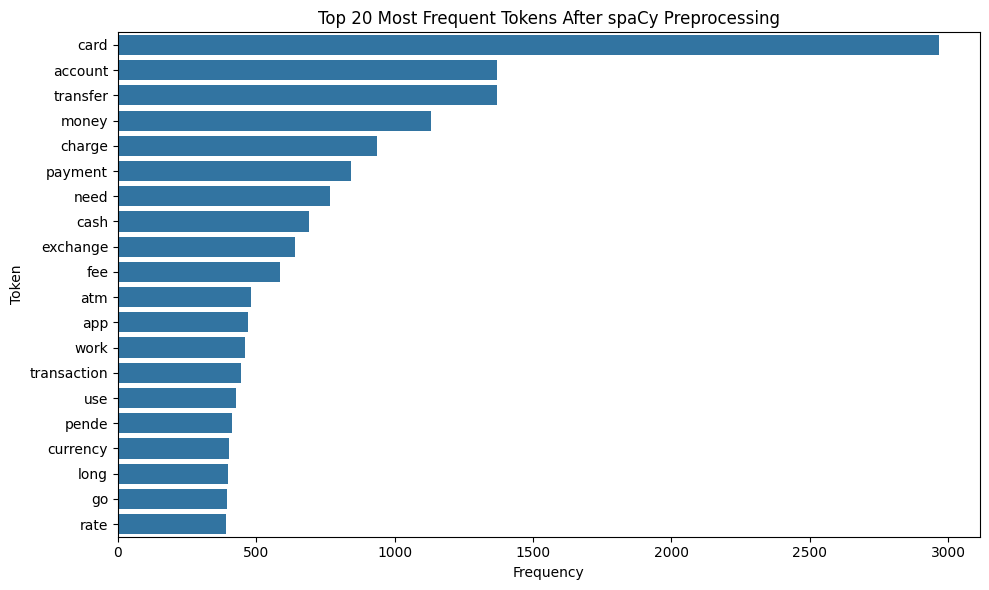

In [23]:
# Apply spaCy preprocessing to all training utterances and collect the resulting tokens.
all_tokens = []

for text in train_df["text"]:
    all_tokens.extend(preprocess_spacy(text))

# Count the frequency of each token across the corpus.
token_freq = Counter(all_tokens)

# Extract the 20 most frequent tokens for analysis.
top_tokens = pd.DataFrame(
    token_freq.most_common(20),
    columns=["Token", "Frequency"]
)

# Display the most frequent tokens and their occurrence counts.
display(top_tokens)

# Visualize the top 20 tokens using a horizontal bar chart.
plt.figure(figsize=(10, 6))
sns.barplot(data=top_tokens, x="Frequency", y="Token")

# Add a descriptive title to the figure.
plt.title("Top 20 Most Frequent Tokens After spaCy Preprocessing")

# Adjust spacing for improved readability.
plt.tight_layout()

# Display the chart.
plt.show()

### spaCy NER Pass

,Entity Type,Frequency
0,ORG,92
1,DATE,49
4,GPE,27
2,TIME,17
3,CARDINAL,16
6,MONEY,10
8,ORDINAL,10
9,NORP,7
7,LOC,3
5,FAC,2


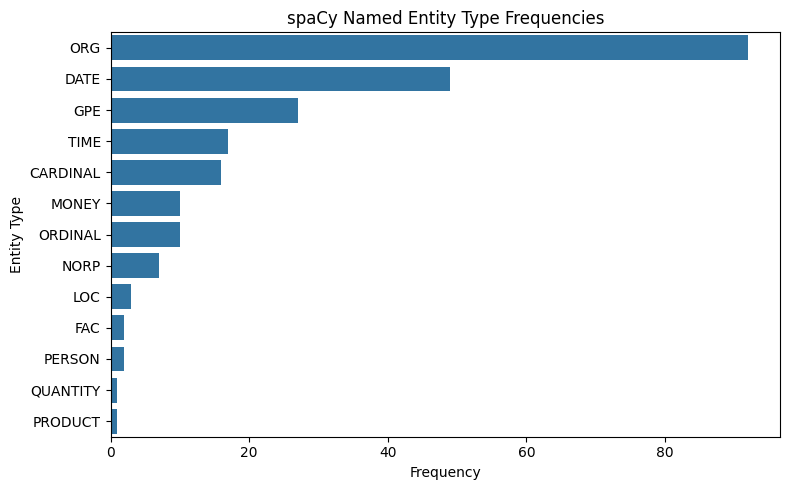

In [24]:
# Initialize a counter to track the frequency of named entity categories.
entity_counter = Counter()

# Analyze a representative sample of utterances using spaCy's NER component.
for text in train_df["text"].sample(1000, random_state=SEED):

    doc = nlp(text)

    # Count each detected entity type.
    for ent in doc.ents:
        entity_counter[ent.label_] += 1

# Convert entity frequencies into a structured DataFrame.
entity_df = pd.DataFrame(
    entity_counter.items(),
    columns=["Entity Type", "Frequency"]
)

# Sort entity types by frequency in descending order.
entity_df = entity_df.sort_values(by="Frequency", ascending=False)

# Display the named entity frequency table.
display(entity_df)

# Visualize the distribution of detected entity categories.
plt.figure(figsize=(8, 5))
sns.barplot(data=entity_df, x="Frequency", y="Entity Type")

# Add a descriptive title to the chart.
plt.title("spaCy Named Entity Type Frequencies")

# Adjust layout for improved readability.
plt.tight_layout()

# Display the visualization.
plt.show()

### Stopword Experiment

In [25]:
# Create separate token collections to compare preprocessing with and without stopword removal.
tokens_with_stopwords = []
tokens_without_stopwords = []

# Process a sample of utterances under both preprocessing settings.
for text in train_df["text"].sample(1000, random_state=SEED):

    tokens_with_stopwords.extend(
        preprocess_spacy(text, remove_stopwords=False)
    )

    tokens_without_stopwords.extend(
        preprocess_spacy(text, remove_stopwords=True)
    )

# Compare vocabulary sizes produced by the two approaches.
print("Vocabulary size WITH stopwords:", len(set(tokens_with_stopwords)))
print("Vocabulary size WITHOUT stopwords:", len(set(tokens_without_stopwords)))

# Display the most frequent tokens when stopwords are retained.
print("\nTop tokens WITH stopwords:")
display(
    pd.DataFrame(
        Counter(tokens_with_stopwords).most_common(10),
        columns=["Token", "Frequency"]
    )
)

# Display the most frequent tokens after stopword removal.
print("\nTop tokens WITHOUT stopwords:")
display(
    pd.DataFrame(
        Counter(tokens_without_stopwords).most_common(10),
        columns=["Token", "Frequency"]
    )
)

Vocabulary size WITH stopwords: 760
Vocabulary size WITHOUT stopwords: 614

Top tokens WITH stopwords:


,Token,Frequency
0,I,1010
1,be,614
2,my,577
3,to,432
4,a,372
5,do,357
6,the,349
7,card,326
8,it,222
9,can,210



Top tokens WITHOUT stopwords:


,Token,Frequency
0,card,326
1,transfer,139
2,account,137
3,money,117
4,charge,91
5,payment,83
6,cash,73
7,need,72
8,exchange,64
9,fee,57


## Task 2 — Classical NLP Baseline for Intent Classification

This task develops and evaluates traditional machine learning models for intent classification using TF-IDF features. Logistic Regression, Naive Bayes, and Linear SVM are compared to establish baseline chatbot performance and identify limitations of classical NLP approaches.

### Prepare Train/Test Data

In [26]:
# Separate the training texts and their corresponding intent labels.
X_train = train_df["text"]
y_train = train_df["label"]

# Separate the test texts and their corresponding intent labels.
X_test = test_df["text"]
y_test = test_df["label"]

# Display the number of training samples available for model development.
print("Train size:", len(X_train))

# Display the number of test samples available for evaluation.
print("Test size:", len(X_test))

# Report the total number of intent categories in the dataset.
print("Number of labels:", len(label_names))

Train size: 9993
Test size: 3076
Number of labels: 77


### TF-IDF Features

In [27]:
# Initialize a TF-IDF vectorizer to convert text into numerical feature representations.
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=10000
)

# Learn the vocabulary from the training data and transform the texts into TF-IDF vectors.
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform the test data using the vocabulary learned from the training set.
X_test_tfidf = tfidf.transform(X_test)

# Display the dimensions of the resulting training feature matrix.
print("TF-IDF training matrix shape:", X_train_tfidf.shape)

# Display the dimensions of the resulting test feature matrix.
print("TF-IDF test matrix shape:", X_test_tfidf.shape)

TF-IDF training matrix shape: (9993, 10000)
TF-IDF test matrix shape: (3076, 10000)


### Train Logistic Regression

In [28]:
# Record the start time to measure model training duration.
start_time = time.time()

# Initialize the Logistic Regression classifier for multi-class intent classification.
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=SEED
)

# Train the model using TF-IDF feature representations.
lr_model.fit(X_train_tfidf, y_train)

# Calculate the total training time.
lr_time = time.time() - start_time

# Generate predictions on the test dataset.
lr_preds = lr_model.predict(X_test_tfidf)

# Compute overall classification accuracy.
lr_acc = accuracy_score(y_test, lr_preds)

# Calculate weighted precision, recall, and F1-score across all classes.
lr_precision, lr_recall, lr_f1, _ = precision_recall_fscore_support(
    y_test,
    lr_preds,
    average="weighted",
    zero_division=0
)

# Display the evaluation results for the Logistic Regression model.
print("Logistic Regression Results")
print("Accuracy:", lr_acc)
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1:", lr_f1)
print("Training time:", lr_time)

Logistic Regression Results
Accuracy: 0.8338751625487646
Precision: 0.8415970416669756
Recall: 0.8338751625487646
F1: 0.8337875747526879
Training time: 12.589548110961914


### Train Naive Bayes

In [29]:
# Record the start time to measure the training efficiency of the Naive Bayes model.
start_time = time.time()

# Initialize the Multinomial Naive Bayes classifier.
nb_model = MultinomialNB()

# Train the classifier using the TF-IDF feature matrix.
nb_model.fit(X_train_tfidf, y_train)

# Calculate the total training time.
nb_time = time.time() - start_time

# Generate predictions for the test dataset.
nb_preds = nb_model.predict(X_test_tfidf)

# Compute overall classification accuracy.
nb_acc = accuracy_score(y_test, nb_preds)

# Calculate weighted precision, recall, and F1-score.
nb_precision, nb_recall, nb_f1, _ = precision_recall_fscore_support(
    y_test,
    nb_preds,
    average="weighted",
    zero_division=0
)

# Display the evaluation results for the Naive Bayes classifier.
print("Naive Bayes Results")
print("Accuracy:", nb_acc)
print("Precision:", nb_precision)
print("Recall:", nb_recall)
print("F1:", nb_f1)
print("Training time:", nb_time)

Naive Bayes Results
Accuracy: 0.770481144343303
Precision: 0.8118965690128231
Recall: 0.770481144343303
F1: 0.7616213733794103
Training time: 0.03437924385070801


### Train Linear SVM

In [30]:
# Record the start time to evaluate the computational cost of model training.
start_time = time.time()

# Initialize a Linear Support Vector Machine classifier for multi-class intent classification.
svm_model = LinearSVC(
    class_weight="balanced",
    random_state=SEED
)

# Train the classifier using TF-IDF feature vectors.
svm_model.fit(X_train_tfidf, y_train)

# Compute the total training time.
svm_time = time.time() - start_time

# Generate predictions for the test dataset.
svm_preds = svm_model.predict(X_test_tfidf)

# Calculate overall classification accuracy.
svm_acc = accuracy_score(y_test, svm_preds)

# Calculate weighted precision, recall, and F1-score across all intent classes.
svm_precision, svm_recall, svm_f1, _ = precision_recall_fscore_support(
    y_test,
    svm_preds,
    average="weighted",
    zero_division=0
)

# Display the evaluation results for the Linear SVM model.
print("Linear SVM Results")
print("Accuracy:", svm_acc)
print("Precision:", svm_precision)
print("Recall:", svm_recall)
print("F1:", svm_f1)
print("Training time:", svm_time)

Linear SVM Results
Accuracy: 0.8426527958387516
Precision: 0.84746930899904
Recall: 0.8426527958387516
F1: 0.8422251027435876
Training time: 0.9801952838897705


### Classical Model Comparison

In [31]:
# Create a summary table containing the evaluation metrics of all classical models.
classical_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Naive Bayes", "Linear SVM"],
    "Accuracy": [lr_acc, nb_acc, svm_acc],
    "Precision": [lr_precision, nb_precision, svm_precision],
    "Recall": [lr_recall, nb_recall, svm_recall],
    "F1": [lr_f1, nb_f1, svm_f1],
    "Training Time Seconds": [lr_time, nb_time, svm_time]
})

# Sort the models by F1-score to identify the best overall performer.
classical_results = classical_results.sort_values(
    by="F1",
    ascending=False
)

# Display the comparative performance results.
display(classical_results)

,Model,Accuracy,Precision,Recall,F1,Training Time Seconds
2,Linear SVM,0.842653,0.847469,0.842653,0.842225,0.980195
0,Logistic Regression,0.833875,0.841597,0.833875,0.833788,12.589548
1,Naive Bayes,0.770481,0.811897,0.770481,0.761621,0.034379


### Classification Report for Best Classical Model

In [32]:
# Select the best-performing classical model based on the comparative evaluation results.
best_classical_preds = svm_preds
best_classical_name = "Linear SVM"

# Display the name of the selected model.
print(f"Classification Report: {best_classical_name}")

# Generate a detailed classification report containing precision,
# recall, F1-score, and support for each intent category.
print(
    classification_report(
        y_test,
        best_classical_preds,
        labels=list(range(len(label_names))),
        target_names=label_names,
        zero_division=0
    )
)

Classification Report: Linear SVM
                                                  precision    recall  f1-score   support

                                activate_my_card       0.97      0.95      0.96        40
                                       age_limit       1.00      0.97      0.99        40
                         apple_pay_or_google_pay       1.00      0.97      0.99        40
                                     atm_support       0.88      0.92      0.90        39
                                automatic_top_up       0.97      0.95      0.96        40
         balance_not_updated_after_bank_transfer       0.67      0.78      0.72        40
balance_not_updated_after_cheque_or_cash_deposit       0.92      0.82      0.87        40
                         beneficiary_not_allowed       0.90      0.90      0.90        40
                                 cancel_transfer       0.90      0.95      0.93        40
                            card_about_to_expire       0.97      

### Confusion Matrix

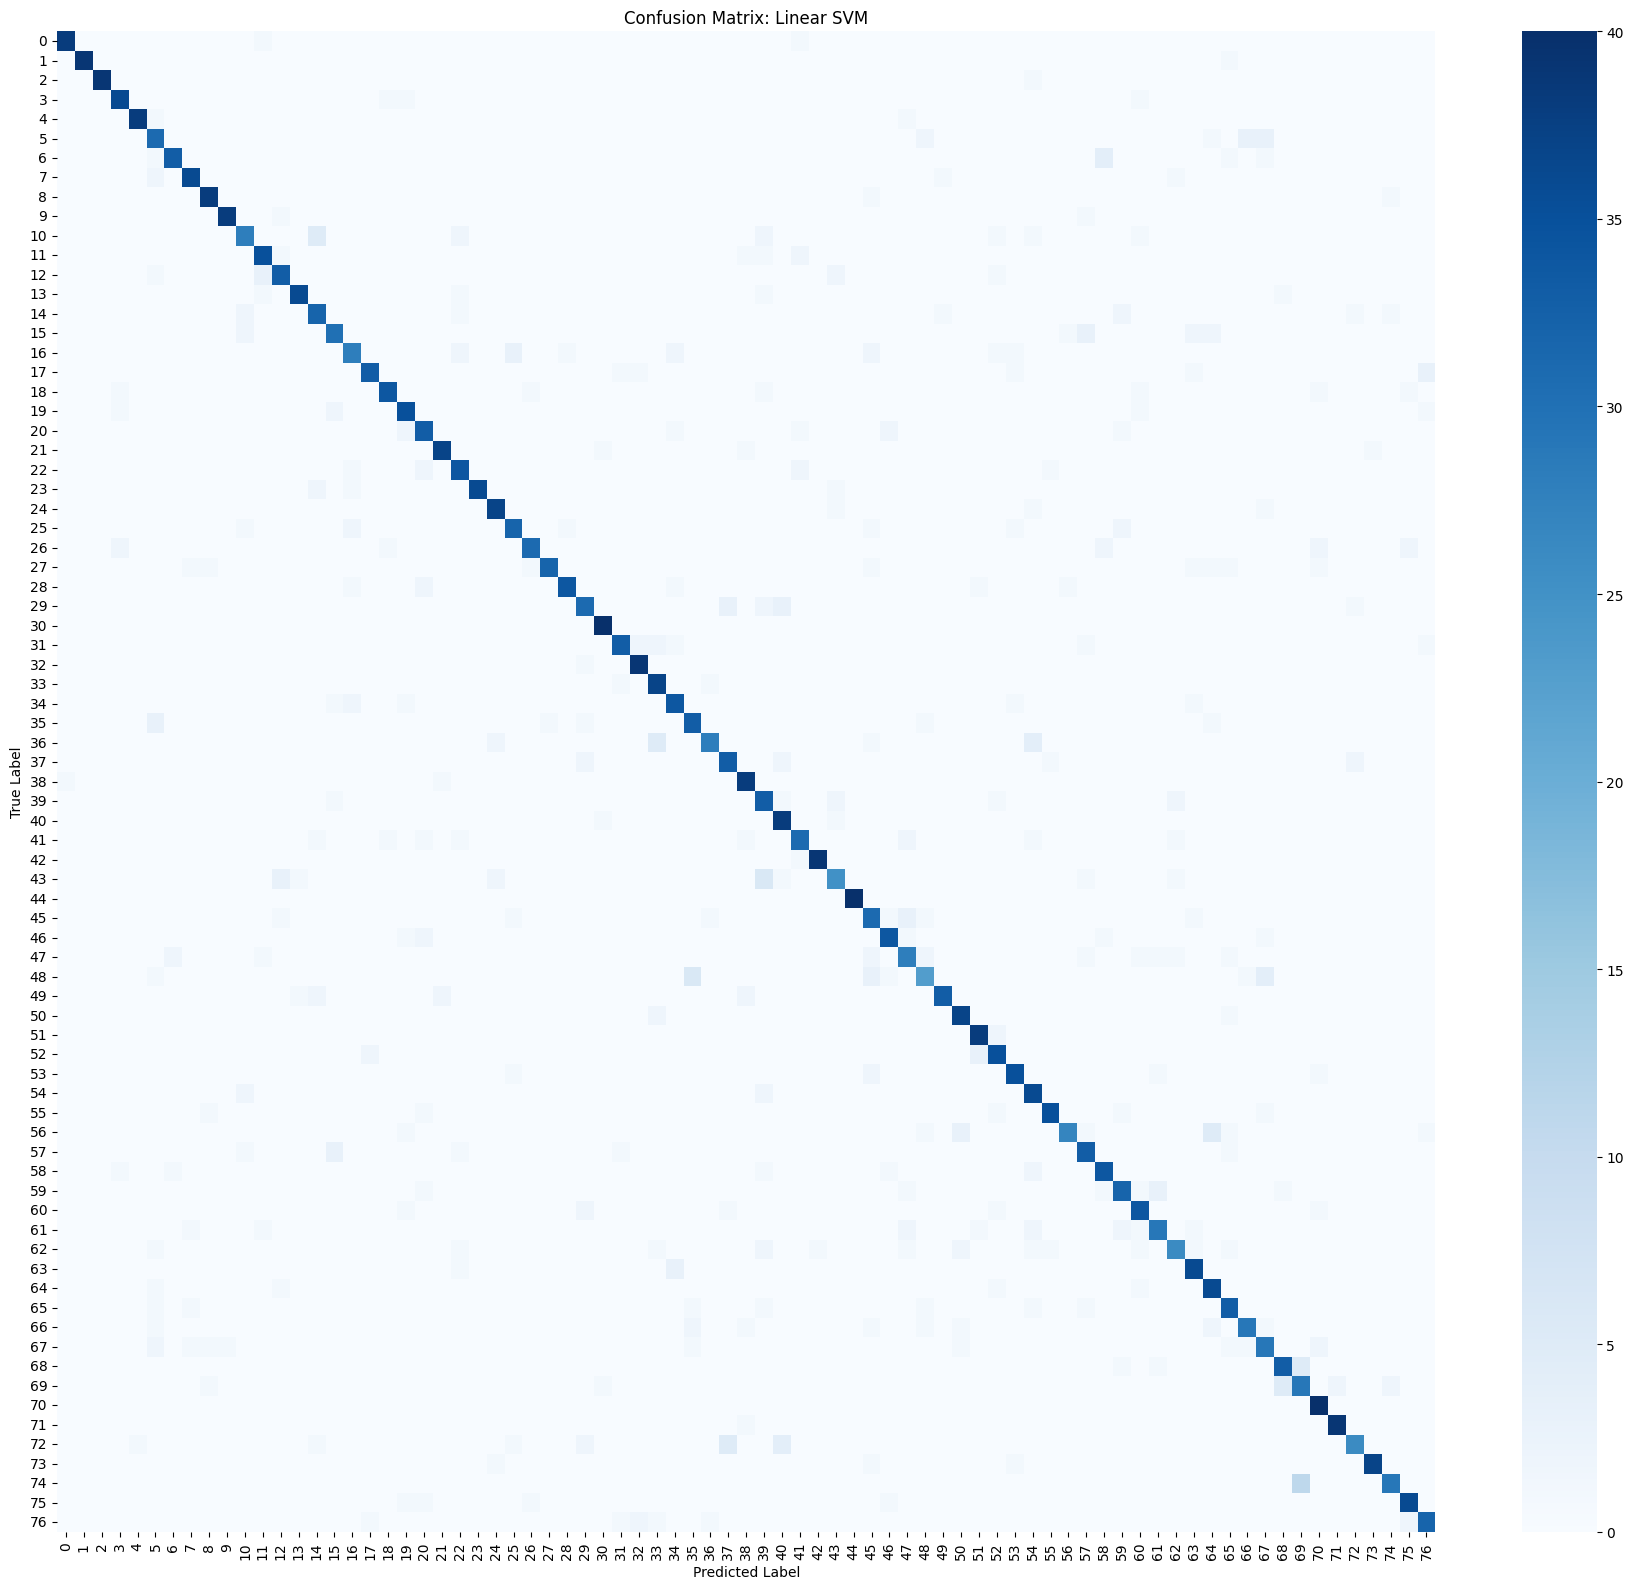

,True Intent,Predicted Intent,Count
315,why_verify_identity,verify_my_identity,11
194,pending_transfer,failed_transfer,6
168,order_physical_card,getting_spare_card,6
24,card_acceptance,card_not_working,5
299,unable_to_verify_identity,verify_my_identity,5
310,virtual_card_not_working,get_disposable_virtual_card,5
140,fiat_currency_support,exchange_via_app,5
302,verify_my_identity,unable_to_verify_identity,5
223,top_up_by_bank_transfer_charge,transfer_fee_charged,5
142,fiat_currency_support,supported_cards_and_currencies,4


In [33]:
# Compute the confusion matrix to examine prediction performance across all intent classes.
cm = confusion_matrix(
    y_test,
    best_classical_preds,
    labels=list(range(len(label_names)))
)

# Visualize the confusion matrix as a heatmap.
plt.figure(figsize=(18, 16))
sns.heatmap(cm, cmap="Blues")

# Add descriptive labels and title for interpretation.
plt.title(f"Confusion Matrix: {best_classical_name}")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Adjust layout to improve readability.
plt.tight_layout()

# Display the confusion matrix.
plt.show()

# Identify the most frequent misclassification patterns between intent classes.
confusion_pairs = []

for true_label in range(len(label_names)):
    for pred_label in range(len(label_names)):

        # Exclude correctly classified instances and retain only errors.
        if true_label != pred_label and cm[true_label, pred_label] > 0:
            confusion_pairs.append({
                "True Intent": label_names[true_label],
                "Predicted Intent": label_names[pred_label],
                "Count": cm[true_label, pred_label]
            })

# Convert confusion pairs into a DataFrame and rank them by error frequency.
confusion_pairs_df = pd.DataFrame(confusion_pairs).sort_values(
    by="Count",
    ascending=False
)

# Display the most common intent confusions.
display(confusion_pairs_df.head(15))

### Misclassified Examples

In [34]:
# Create a copy of the test dataset to store prediction results and error analysis outputs.
errors_df = test_df.copy()

# Add the predicted numerical labels generated by the best classical model.
errors_df["predicted_label"] = best_classical_preds

# Convert predicted label indices into their corresponding intent names.
errors_df["predicted_intent"] = errors_df["predicted_label"].apply(
    lambda x: label_names[x]
)

# Identify whether each prediction is correct.
errors_df["correct"] = (
    errors_df["label"] == errors_df["predicted_label"]
)

# Extract only the misclassified examples for qualitative error analysis.
misclassified = errors_df[errors_df["correct"] == False]

# Display a random sample of misclassified utterances along with
# their true and predicted intent labels.
display(
    misclassified[
        ["text", "intent", "predicted_intent"]
    ].sample(10, random_state=SEED)
)

,text,intent,predicted_intent
2618,how does a virtual card work,get_disposable_virtual_card,virtual_card_not_working
3010,What's the process for ID verification?,verify_my_identity,unable_to_verify_identity
1105,I have an unauthorized transaction on my state...,card_payment_not_recognised,extra_charge_on_statement
2757,whats your exchange rate,exchange_charge,exchange_rate
1859,When will my transfer go through?,pending_transfer,failed_transfer
977,"I am traveling to Germany, Will I be able to u...",card_acceptance,card_not_working
2479,Where can I get my card at?,order_physical_card,getting_spare_card
2496,How much does it cost in fees to use your card?,order_physical_card,top_up_by_card_charge
3033,What all am I required to show for the identit...,verify_my_identity,why_verify_identity
1384,Can you explain the virtual cards limit?,disposable_card_limits,getting_virtual_card


### Optional NER Features

In [35]:
# Define the named entity categories to be used as additional linguistic features.
entity_types = ["PERSON", "ORG", "GPE", "DATE", "MONEY", "CARDINAL"]

# Extract entity count features from a text instance using spaCy's NER model.
def extract_ner_features(text):

    # Process the text and identify named entities.
    doc = nlp(str(text))

    # Count the occurrences of each entity type.
    counts = Counter([ent.label_ for ent in doc.ents])

    # Return a feature vector containing counts for the selected entity categories.
    return [counts.get(entity, 0) for entity in entity_types]

# Generate NER-based feature vectors for the training dataset.
train_ner_features = np.array([
    extract_ner_features(text)
    for text in X_train
])

# Generate NER-based feature vectors for the test dataset.
test_ner_features = np.array([
    extract_ner_features(text)
    for text in X_test
])

# Display the dimensions of the extracted NER feature matrix.
print("NER feature shape:", train_ner_features.shape)

NER feature shape: (9993, 6)


### Combine TF-IDF + NER Features

In [36]:
# Import hstack to combine sparse TF-IDF features with dense NER-based features.
from scipy.sparse import hstack

# Combine TF-IDF vectors and NER count features for the training data.
X_train_combined = hstack([X_train_tfidf, train_ner_features])

# Combine TF-IDF vectors and NER count features for the test data.
X_test_combined = hstack([X_test_tfidf, test_ner_features])

# Initialize a Linear SVM model using the expanded feature representation.
ner_svm_model = LinearSVC(
    class_weight="balanced",
    random_state=SEED
)

# Record training time for the enhanced feature-based model.
start_time = time.time()

# Train the model using both lexical and named entity features.
ner_svm_model.fit(X_train_combined, y_train)

# Calculate the total training duration.
ner_svm_time = time.time() - start_time

# Generate predictions on the combined test feature matrix.
ner_svm_preds = ner_svm_model.predict(X_test_combined)

# Compute the accuracy of the TF-IDF plus NER model.
ner_svm_acc = accuracy_score(y_test, ner_svm_preds)

# Compute weighted precision, recall, and F1-score across all intent classes.
ner_svm_precision, ner_svm_recall, ner_svm_f1, _ = precision_recall_fscore_support(
    y_test,
    ner_svm_preds,
    average="weighted",
    zero_division=0
)

# Display the evaluation results for the combined-feature Linear SVM model.
print("TF-IDF + NER Linear SVM Results")
print("Accuracy:", ner_svm_acc)
print("Precision:", ner_svm_precision)
print("Recall:", ner_svm_recall)
print("F1:", ner_svm_f1)
print("Training time:", ner_svm_time)

TF-IDF + NER Linear SVM Results
Accuracy: 0.846553966189857
Precision: 0.8520526055439204
Recall: 0.846553966189857
F1: 0.8460860666531536
Training time: 0.7962546348571777


## Task 3 — Semantic Embeddings for Retrieval-Based Chatbots

This task explores semantic word representations using Word2Vec embeddings. The objective is to analyse semantic similarity, visualise embedding relationships, and demonstrate how retrieval-based chatbots can use vector representations to match user queries with relevant responses.

### Prepare Tokenised Corpus

In [37]:
tokenised_corpus = [preprocess_spacy(text) for text in train_df["text"]]

display(tokenised_corpus[:3])

[['wait', 'card'],
 ['card', 'arrive', 'week'],
 ['wait', 'week', 'card', 'come']]

### Train Word2Vec Model

In [38]:
w2v_model = Word2Vec(
    sentences=tokenised_corpus,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=0,
    seed=SEED
)

print("Vocabulary size:", len(w2v_model.wv))

Vocabulary size: 926


### Word Similarity Examples

In [39]:
# Select representative banking-related terms for semantic similarity analysis.
test_words = ["card", "transfer", "payment", "cash", "account"]

# Retrieve the nearest semantic neighbors for each query word.
for word in test_words:

    # Check whether the word exists in the trained Word2Vec vocabulary.
    if word in w2v_model.wv:

        print(f"\nMost similar words to '{word}':")

        # Display the top ten most similar words and their cosine similarity scores.
        display(
            pd.DataFrame(
                w2v_model.wv.most_similar(word, topn=10),
                columns=["Similar Word", "Similarity"]
            )
        )

    else:
        # Report words that are not present in the learned vocabulary.
        print(f"'{word}' not found in Word2Vec vocabulary.")


Most similar words to 'card':


,Similar Word,Similarity
0,new,0.997225
1,order,0.997131
2,credit,0.997108
3,access,0.996966
4,tell,0.996865
5,way,0.996856
6,restriction,0.996767
7,place,0.996733
8,freeze,0.996654
9,find,0.996636



Most similar words to 'transfer':


,Similar Word,Similarity
0,long,0.998204
1,take,0.998137
2,seller,0.997930
3,complete,0.997790
4,morning,0.997782
5,uk,0.997717
6,go,0.997695
7,account,0.997667
8,wait,0.997653
9,send,0.997613



Most similar words to 'payment':


,Similar Word,Similarity
0,transaction,0.998582
1,recognize,0.998246
2,show,0.997799
3,see,0.997718
4,revert,0.997716
5,app,0.997652
6,dispute,0.997589
7,sure,0.997585
8,look,0.997532
9,statement,0.997488



Most similar words to 'cash':


,Similar Word,Similarity
0,atm,0.996342
1,wrong,0.995685
2,incorrect,0.994932
3,purchase,0.994863
4,notice,0.994742
5,abroad,0.994730
6,correct,0.994726
7,different,0.994601
8,withdraw,0.994560
9,free,0.994492



Most similar words to 'account':


,Similar Word,Similarity
0,bank,0.998576
1,yesterday,0.998543
2,process,0.998505
3,hour,0.998469
4,morning,0.998465
5,go,0.998413
6,complete,0.998391
7,uk,0.998370
8,check,0.998365
9,hi,0.998329


### Cosine Similarity Table

In [40]:
# Define selected banking-related word pairs for semantic similarity evaluation.
word_pairs = [
    ("card", "payment"),
    ("card", "cash"),
    ("transfer", "payment"),
    ("account", "bank"),
    ("cash", "withdraw")
]

similarity_rows = []

# Compute cosine similarity scores between each pair of words.
for w1, w2 in word_pairs:

    # Ensure that both words are present in the Word2Vec vocabulary.
    if w1 in w2v_model.wv and w2 in w2v_model.wv:

        similarity_rows.append({
            "Word 1": w1,
            "Word 2": w2,
            "Cosine Similarity": w2v_model.wv.similarity(w1, w2)
        })

# Convert the similarity results into a DataFrame for inspection.
similarity_df = pd.DataFrame(similarity_rows)

# Display the semantic similarity scores for the selected word pairs.
display(similarity_df)

,Word 1,Word 2,Cosine Similarity
0,card,payment,0.993820
1,card,cash,0.984180
2,transfer,payment,0.994256
3,account,bank,0.998577
4,cash,withdraw,0.994560


### Visualise Embeddings with PCA

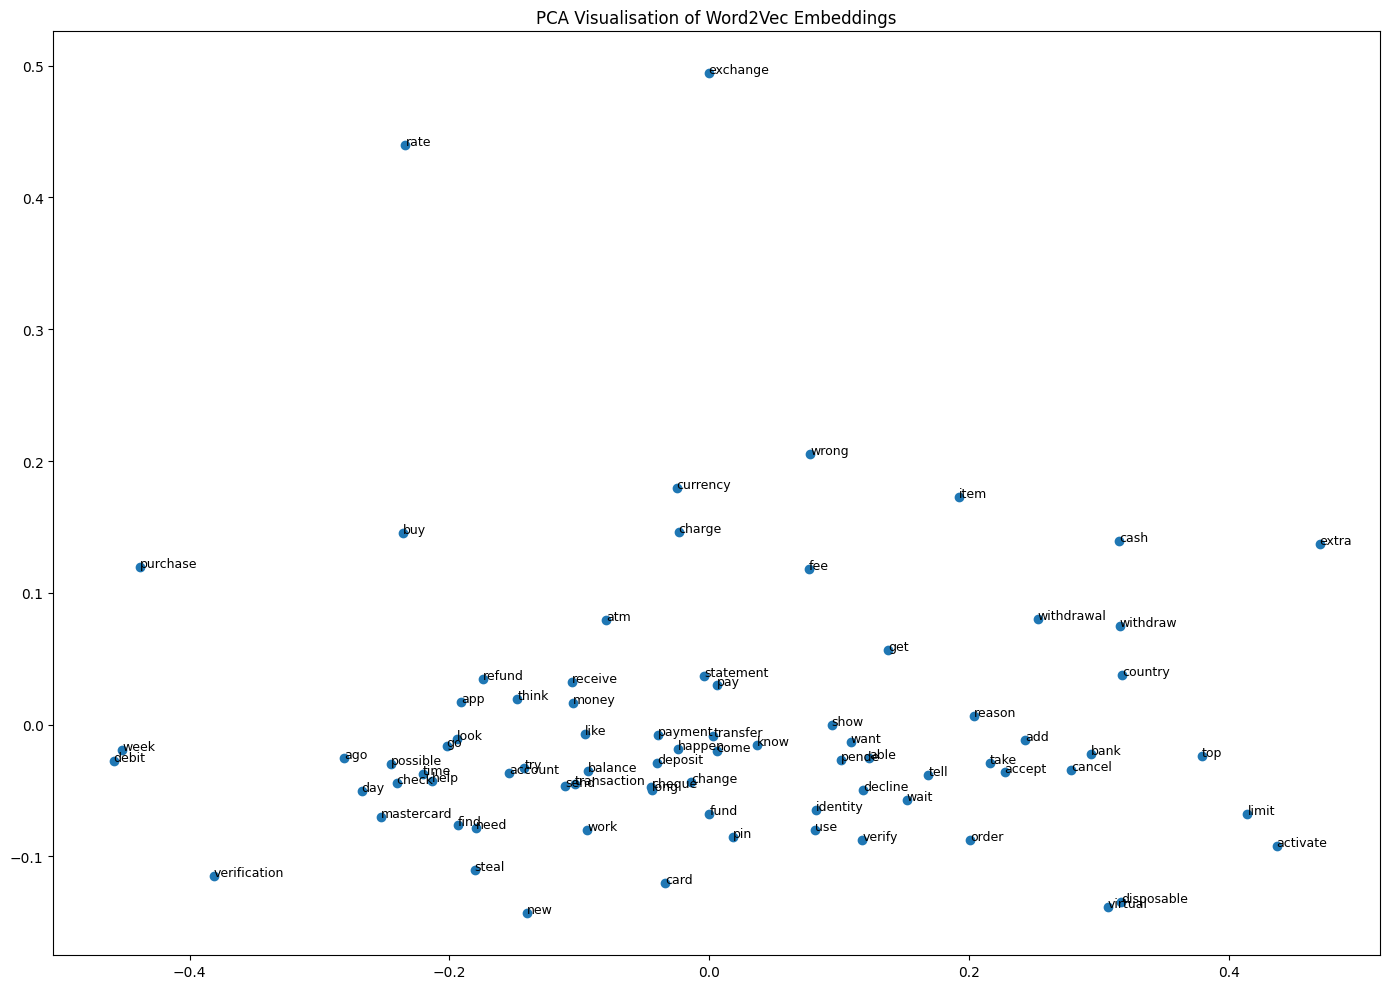

In [41]:
# Select the most frequent tokens that are also present in the Word2Vec vocabulary.
selected_words = [
    word for word, count in token_freq.most_common(80)
    if word in w2v_model.wv
]

# Retrieve the Word2Vec embedding vector for each selected word.
word_vectors = np.array([
    w2v_model.wv[word]
    for word in selected_words
])

# Reduce the high-dimensional word embeddings to two dimensions using PCA.
pca = PCA(
    n_components=2,
    random_state=SEED
)

# Fit PCA on the word vectors and transform them into a two-dimensional representation.
pca_result = pca.fit_transform(word_vectors)

# Create a scatter plot to visualize semantic relationships between selected words.
plt.figure(figsize=(14, 10))
plt.scatter(pca_result[:, 0], pca_result[:, 1])

# Annotate each point with its corresponding token.
for i, word in enumerate(selected_words):
    plt.annotate(
        word,
        xy=(pca_result[i, 0], pca_result[i, 1]),
        fontsize=9
    )

# Add a descriptive title to the visualization.
plt.title("PCA Visualisation of Word2Vec Embeddings")

# Adjust the layout to prevent text and figure elements from overlapping.
plt.tight_layout()

# Display the PCA-based embedding visualization.
plt.show()

### Sentence Embedding Function

In [42]:
# Define a function to generate a fixed-length sentence embedding
# by averaging the Word2Vec vectors of the constituent tokens.
def sentence_vector(text, model):

    # Preprocess the input text using the spaCy-based pipeline.
    tokens = preprocess_spacy(text)

    vectors = []

    # Retrieve Word2Vec embeddings for tokens present in the vocabulary.
    for token in tokens:
        if token in model.wv:
            vectors.append(model.wv[token])

    # Return a zero vector if no valid token embeddings are found.
    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    # Compute the mean embedding to obtain the sentence representation.
    return np.mean(vectors, axis=0)

### Build Retrieval Index

In [43]:
# Select a representative subset of training examples for similarity-based retrieval experiments.
retrieval_sample = train_df.sample(
    3000,
    random_state=SEED
).reset_index(drop=True)

# Generate sentence embeddings for each utterance using the averaged Word2Vec representation.
sentence_vectors = np.array([
    sentence_vector(text, w2v_model)
    for text in retrieval_sample["text"]
])

# Display the dimensions of the resulting sentence embedding matrix.
print("Sentence vector matrix shape:", sentence_vectors.shape)

Sentence vector matrix shape: (3000, 100)


### Retrieval Function

In [44]:
# Import cosine similarity for measuring semantic similarity between sentence embeddings.
from sklearn.metrics.pairwise import cosine_similarity

# Define a retrieval function that returns the most semantically similar utterances.
def retrieve_similar_sentences(query, top_k=5):

    # Generate a sentence embedding for the input query.
    query_vec = sentence_vector(
        query,
        w2v_model
    ).reshape(1, -1)

    # Compute cosine similarity between the query and all stored sentence embeddings.
    similarities = cosine_similarity(
        query_vec,
        sentence_vectors
    )[0]

    # Identify the indices of the top-k most similar utterances.
    top_indices = similarities.argsort()[::-1][:top_k]

    # Retrieve the corresponding examples from the sampled dataset.
    results = retrieval_sample.iloc[top_indices].copy()

    # Attach similarity scores for ranking and interpretation.
    results["similarity"] = similarities[top_indices]

    # Return the retrieved utterances, their intents, and similarity values.
    return results[["text", "intent", "similarity"]]

### Retrieval Demo

In [46]:
# Define a sample customer query related to card delivery.
query = "I have not received my new bank card yet"

# Retrieve the top five most semantically similar utterances from the corpus.
retrieval_results = retrieve_similar_sentences(
    query,
    top_k=5
)

# Display the input query for reference.
print("User query:", query)

# Display the retrieved utterances, associated intents, and similarity scores.
display(retrieval_results)

User query: I have not received my new bank card yet


,text,intent,similarity
2782,Why haven't I received my new card yet?,card_arrival,0.999886
278,Can you tell me why I haven't received my new ...,card_arrival,0.999885
1500,Where can I have a new bank card sent to China?,card_about_to_expire,0.999883
2451,How long should it take for my new card to arr...,card_arrival,0.999867
1974,How do I know when my new card is going to arr...,card_arrival,0.999824


## Task 4 — Fine-Tuning a Transformer for Intent Recognition

This task fine-tunes DistilBERT for banking intent classification and compares its performance against classical machine learning models. The evaluation focuses on accuracy, contextual understanding, computational requirements, and the practical implications of deploying transformer models in chatbot applications.

### Prepare Hugging Face Dataset

In [47]:
hf_dataset = dataset

print(hf_dataset)
print("Number of labels:", len(label_names))
print("First 10 labels:", label_names[:10])

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 9993
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 3076
    })
})
Number of labels: 77
First 10 labels: ['activate_my_card', 'age_limit', 'apple_pay_or_google_pay', 'atm_support', 'automatic_top_up', 'balance_not_updated_after_bank_transfer', 'balance_not_updated_after_cheque_or_cash_deposit', 'beneficiary_not_allowed', 'cancel_transfer', 'card_about_to_expire']


### Tokenizer

In [54]:
# Specify the pretrained DistilBERT checkpoint to be used for transformer-based classification.
model_checkpoint = "distilbert-base-uncased"

# Load the corresponding tokenizer for text encoding.
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

# Define a tokenization function to convert raw text into model-compatible inputs.
def tokenize_function(batch):

    return tokenizer(
        batch["text"],

        # Truncate sequences exceeding the maximum length.
        truncation=True,

        # Apply dynamic padding later through a data collator.
        padding=False,

        # Limit sequence length to improve computational efficiency.
        max_length=64
    )

# Apply tokenization to the entire Hugging Face dataset.
tokenized_dataset = hf_dataset.map(
    tokenize_function,
    batched=True
)

# Display the structure of the tokenized dataset.
print(tokenized_dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 9993
    })
    test: Dataset({
        features: ['text', 'label', 'label_text', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3076
    })
})


### Data Collator

In [55]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

### Evaluation Metrics

In [56]:
# Define a custom evaluation function for monitoring model performance during training.
def compute_metrics(eval_pred):

    # Extract model outputs and true labels from the evaluation batch.
    logits, labels = eval_pred

    # Convert prediction scores into class labels.
    predictions = np.argmax(logits, axis=-1)

    # Compute overall classification accuracy.
    accuracy = accuracy_score(labels, predictions)

    # Calculate weighted precision, recall, and F1-score.
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    # Return evaluation metrics in a dictionary format compatible with Trainer.
    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

### Load DistilBERT Model

In [57]:
# Determine the total number of intent classes in the dataset.
num_labels = len(label_names)

# Create a mapping from numerical label IDs to human-readable intent names.
id2label = {
    i: label
    for i, label in enumerate(label_names)
}

# Create the reverse mapping from intent names to numerical label IDs.
label2id = {
    label: i
    for i, label in enumerate(label_names)
}

# Load a pretrained DistilBERT model and adapt it for multi-class intent classification.
model = AutoModelForSequenceClassification.from_pretrained(
    model_checkpoint,

    # Specify the number of output classes.
    num_labels=num_labels,

    # Provide label mappings for improved interpretability of predictions.
    id2label=id2label,
    label2id=label2id
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### Training Arguments

In [58]:
# Define the training configuration for fine-tuning the DistilBERT model.
training_args = TrainingArguments(

    # Directory where model checkpoints and outputs will be stored.
    output_dir="./distilbert-banking77",

    # Initial learning rate for the AdamW optimizer.
    learning_rate=2e-5,

    # Batch size used during training.
    per_device_train_batch_size=16,

    # Batch size used during evaluation.
    per_device_eval_batch_size=16,

    # Number of complete passes through the training dataset.
    num_train_epochs=3,

    # Apply weight decay regularization to reduce overfitting.
    weight_decay=0.01,

    # Evaluate model performance at the end of each epoch.
    eval_strategy="epoch",

    # Save model checkpoints after each epoch.
    save_strategy="epoch",

    # Enable periodic training logs.
    logging_strategy="steps",

    # Log training progress every 50 steps.
    logging_steps=50,

    # Reload the checkpoint with the best evaluation score after training.
    load_best_model_at_end=True,

    # Use weighted F1-score as the criterion for selecting the best model.
    metric_for_best_model="f1",

    # Disable external experiment tracking services.
    report_to="none",

    # Set a fixed random seed to support reproducibility.
    seed=SEED
)

### Trainer

In [60]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["test"],
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

### Train DistilBERT

In [61]:
# Record the start time to measure the total fine-tuning duration.
start_time = time.time()

# Fine-tune the DistilBERT model on the Banking77 training dataset.
trainer.train()

# Compute the total training time after model training is completed.
transformer_training_time = time.time() - start_time

# Display the overall training duration in seconds.
print(
    "Transformer training time in seconds:",
    transformer_training_time
)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,2.234253,1.992212,0.690182,0.691686,0.690182,0.644863
2,1.103824,1.066816,0.814694,0.815426,0.814694,0.796048
3,0.858212,0.860526,0.853056,0.846093,0.853056,0.842509


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


Transformer training time in seconds: 173.35363507270813


### Evaluate DistilBERT

In [62]:
transformer_metrics = trainer.evaluate()

display(transformer_metrics)

{'eval_loss': 0.8605257272720337,
 'eval_accuracy': 0.8530559167750326,
 'eval_precision': 0.8460933161919582,
 'eval_recall': 0.8530559167750326,
 'eval_f1': 0.8425089669562924,
 'eval_runtime': 3.7039,
 'eval_samples_per_second': 830.471,
 'eval_steps_per_second': 52.107,
 'epoch': 3.0}

### Transformer Predictions

In [63]:
# Generate predictions for the test split using the fine-tuned transformer model.
predictions_output = trainer.predict(
    tokenized_dataset["test"]
)

# Extract the raw output logits produced by the model.
transformer_logits = predictions_output.predictions

# Convert logits into predicted class labels by selecting the highest-scoring class.
transformer_preds = np.argmax(
    transformer_logits,
    axis=-1
)

# Generate a detailed classification report containing precision,
# recall, F1-score, and support for each intent category.
print(
    classification_report(
        y_test,
        transformer_preds,
        labels=list(range(len(label_names))),
        target_names=label_names,
        zero_division=0
    )
)

                                                  precision    recall  f1-score   support

                                activate_my_card       1.00      0.93      0.96        40
                                       age_limit       1.00      1.00      1.00        40
                         apple_pay_or_google_pay       1.00      1.00      1.00        40
                                     atm_support       0.95      0.97      0.96        39
                                automatic_top_up       1.00      0.90      0.95        40
         balance_not_updated_after_bank_transfer       0.71      0.75      0.73        40
balance_not_updated_after_cheque_or_cash_deposit       0.95      0.95      0.95        40
                         beneficiary_not_allowed       0.92      0.85      0.88        40
                                 cancel_transfer       1.00      0.93      0.96        40
                            card_about_to_expire       0.95      0.93      0.94        40
         

### Transformer Misclassified Examples

In [64]:
# Create a copy of the test dataset for transformer-based error analysis.
transformer_errors_df = test_df.copy()

# Store the predicted class labels generated by the fine-tuned transformer model.
transformer_errors_df["predicted_label"] = transformer_preds

# Convert numerical predictions into human-readable intent names.
transformer_errors_df["predicted_intent"] = (
    transformer_errors_df["predicted_label"]
    .apply(lambda x: label_names[x])
)

# Determine whether each prediction matches the true label.
transformer_errors_df["correct"] = (
    transformer_errors_df["label"]
    == transformer_errors_df["predicted_label"]
)

# Extract only the incorrectly classified examples.
transformer_misclassified = transformer_errors_df[
    transformer_errors_df["correct"] == False
]

# Display a random sample of transformer misclassifications for qualitative analysis.
display(
    transformer_misclassified[
        ["text", "intent", "predicted_intent"]
    ].sample(
        min(10, len(transformer_misclassified)),
        random_state=SEED
    )
)

,text,intent,predicted_intent
1949,I was taking out funds and was unable to regai...,card_swallowed,declined_cash_withdrawal
377,My card was declined today when eating and I n...,card_not_working,declined_card_payment
2337,What methods can I use to add money to my acco...,transfer_into_account,supported_cards_and_currencies
2319,"I don't understand how to top up my account, c...",transfer_into_account,topping_up_by_card
1101,What should I do to get transactions off of my...,card_payment_not_recognised,compromised_card
1329,Where's the money that got charged to my card?...,topping_up_by_card,extra_charge_on_statement
1922,Is there a way I can get my ATM card back from...,card_swallowed,atm_support
907,I just have one other card from the US. Is tha...,supported_cards_and_currencies,country_support
2565,A wrong exchange rate was applied to a transac...,wrong_exchange_rate_for_cash_withdrawal,card_payment_wrong_exchange_rate
311,When can I expect to receive my new card?,card_delivery_estimate,card_arrival


### Classical vs Transformer Comparison

In [65]:
# Extract the key evaluation metrics obtained from the transformer model.
transformer_acc = transformer_metrics["eval_accuracy"]
transformer_precision = transformer_metrics["eval_precision"]
transformer_recall = transformer_metrics["eval_recall"]
transformer_f1 = transformer_metrics["eval_f1"]

# Create a consolidated comparison table covering all evaluated models.
comparison_table = pd.DataFrame({
    "Model": [
        "Naive Bayes",
        "Logistic Regression",
        "Linear SVM",
        "Linear SVM + NER",
        "DistilBERT"
    ],

    # Overall classification accuracy.
    "Accuracy": [
        nb_acc,
        lr_acc,
        svm_acc,
        ner_svm_acc,
        transformer_acc
    ],

    # Weighted F1-score used as the primary performance metric.
    "F1 Score": [
        nb_f1,
        lr_f1,
        svm_f1,
        ner_svm_f1,
        transformer_f1
    ],

    # Total training time required by each model.
    "Training Time Seconds": [
        nb_time,
        lr_time,
        svm_time,
        ner_svm_time,
        transformer_training_time
    ],

    # Qualitative assessment of model complexity.
    "Model Complexity": [
        "Low",
        "Medium",
        "Medium",
        "Medium",
        "High"
    ],

    # Practical observations regarding chatbot deployment suitability.
    "Chatbot Deployment Comment": [
        "Very fast but weaker with overlapping intents",
        "Interpretable and efficient baseline",
        "Strong classical baseline for sparse text",
        "Tests whether entity signals improve intent detection",
        "Best semantic understanding but most expensive"
    ]
})

# Rank models according to their F1-score.
comparison_table = comparison_table.sort_values(
    by="F1 Score",
    ascending=False
)

# Display the final comparative evaluation table.
display(comparison_table)

,Model,Accuracy,F1 Score,Training Time Seconds,Model Complexity,Chatbot Deployment Comment
3,Linear SVM + NER,0.846554,0.846086,0.796255,Medium,Tests whether entity signals improve intent de...
4,DistilBERT,0.853056,0.842509,173.353635,High,Best semantic understanding but most expensive
2,Linear SVM,0.842653,0.842225,0.980195,Medium,Strong classical baseline for sparse text
1,Logistic Regression,0.833875,0.833788,12.589548,Medium,Interpretable and efficient baseline
0,Naive Bayes,0.770481,0.761621,0.034379,Low,Very fast but weaker with overlapping intents


### Optional Transformer NER

In [66]:
# Initialize a transformer-based Named Entity Recognition (NER) pipeline.
ner_pipeline = pipeline(
    "ner",
    model="dslim/bert-base-NER",
    aggregation_strategy="simple"
)

# Define sample banking-related sentences for NER comparison.
sample_ner_texts = [
    "I transferred 500 pounds to John yesterday but it has not arrived.",
    "My Visa card was declined in London.",
    "I want to open a new account with Barclays."
]

# Compare entity extraction results from the transformer model and spaCy.
for text in sample_ner_texts:

    print("\nText:", text)

    # Apply transformer-based NER and display the detected entities.
    print("\nTransformer NER:")
    display(
        pd.DataFrame(
            ner_pipeline(text)
        )
    )

    # Apply spaCy NER and display the detected entities.
    print("\nspaCy NER:")
    doc = nlp(text)

    display(
        pd.DataFrame(
            [(ent.text, ent.label_) for ent in doc.ents],
            columns=["Entity", "Label"]
        )
    )

config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/433M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/59.0 [00:00<?, ?B/s]

...

,Entity,Label
0,Visa,ORG
1,London,GPE



Text: I want to open a new account with Barclays.

Transformer NER:


,entity_group,score,word,start,end
0,ORG,0.999165,Barclays,34,42



spaCy NER:


,Entity,Label
0,Barclays,ORG


### Optional 50% Dataset Experiment

In [67]:
# Create a smaller training subset containing 50% of the original training data.
small_train = tokenized_dataset["train"].shuffle(seed=SEED).select(
    range(int(len(tokenized_dataset["train"]) * 0.5))
)

# Initialize a separate DistilBERT model for the reduced-data experiment.
small_model = AutoModelForSequenceClassification.from_pretrained(
    model_checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

# Define training arguments for the reduced-data transformer experiment.
small_training_args = TrainingArguments(
    output_dir="./distilbert-banking77-small",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    report_to="none",
    seed=SEED
)

# Create a Trainer instance for fine-tuning the reduced-data model.
small_trainer = Trainer(
    model=small_model,
    args=small_training_args,
    train_dataset=small_train,
    eval_dataset=tokenized_dataset["test"],
    data_collator=data_collator,
    compute_metrics=compute_metrics
)
# Fine-tune the model using the smaller training subset.
small_trainer.train()

# Evaluate the reduced-data model on the test set.
small_metrics = small_trainer.evaluate()

# Display the evaluation metrics for comparison with the full-data model.
display(small_metrics)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,3.490830,3.318685,0.425553,0.489608,0.425553,0.366091
2,2.926645,2.906217,0.510078,0.564785,0.510078,0.459461


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


{'eval_loss': 2.906217336654663,
 'eval_accuracy': 0.5100780234070221,
 'eval_precision': 0.5647846362305023,
 'eval_recall': 0.5100780234070221,
 'eval_f1': 0.4594605701820122,
 'eval_runtime': 3.1663,
 'eval_samples_per_second': 971.471,
 'eval_steps_per_second': 60.954,
 'epoch': 2.0}

## Task 5 — Responsible Conversational AI

This task examines ethical, operational, and safety challenges associated with chatbot deployment. Using insights from previous experiments, potential risks such as intent misclassification, bias, and unreliable predictions are analysed alongside mitigation strategies and emerging trends in conversational AI.

###  Confidence Scores for Transformer

In [68]:
# Import the softmax function to convert model logits into probability distributions.
import torch.nn.functional as F

# Convert transformer output logits into class probabilities.
probabilities = F.softmax(
    torch.tensor(transformer_logits),
    dim=1
).numpy()

# Extract the highest probability for each prediction as a confidence score.
confidence_scores = probabilities.max(axis=1)

# Create a DataFrame for confidence-based prediction analysis.
confidence_df = test_df.copy()

# Store predicted labels generated by the transformer model.
confidence_df["predicted_label"] = transformer_preds

# Map predicted label indices to their corresponding intent names.
confidence_df["predicted_intent"] = confidence_df["predicted_label"].apply(
    lambda x: label_names[x]
)

# Add prediction confidence scores.
confidence_df["confidence"] = confidence_scores

# Identify whether each prediction is correct.
confidence_df["correct"] = (
    confidence_df["label"]
    == confidence_df["predicted_label"]
)

# Display the lowest-confidence predictions for qualitative error analysis.
display(
    confidence_df.sort_values(by="confidence").head(20)[
        [
            "text",
            "intent",
            "predicted_intent",
            "confidence",
            "correct"
        ]
    ]
)

,text,intent,predicted_intent,confidence,correct
2398,I want to order another crad,getting_spare_card,transfer_into_account,0.055922,False
1331,I am missing some funds from my account - I tr...,topping_up_by_card,balance_not_updated_after_bank_transfer,0.063556,False
2296,What are your policies for card transfers?,failed_transfer,transfer_into_account,0.076186,False
965,What stores can I sue my card?,card_acceptance,declined_card_payment,0.077286,False
594,How do I use contactless pay?,contactless_not_working,contactless_not_working,0.078816,True
595,How do I enable contactless pay?,contactless_not_working,contactless_not_working,0.082451,True
573,How do I check my security settings to allow c...,contactless_not_working,contactless_not_working,0.083460,True
293,What is the difference between standard and ex...,card_delivery_estimate,supported_cards_and_currencies,0.084276,False
559,Are contactless payments enabled on my new card?,contactless_not_working,contactless_not_working,0.091350,True
591,How do I use contactless payments?,contactless_not_working,contactless_not_working,0.093467,True


### Low Confidence Fallback Analysis

In [69]:
# Define a confidence threshold for identifying uncertain predictions.
threshold = 0.60

# Select predictions whose confidence scores fall below the threshold.
low_confidence_cases = confidence_df[
    confidence_df["confidence"] < threshold
]

# Report the confidence threshold used in the analysis.
print("Confidence threshold:", threshold)

# Display the number of low-confidence predictions.
print("Number of low confidence cases:", len(low_confidence_cases))

# Calculate the proportion of low-confidence predictions in the test set.
print(
    "Percentage of test set:",
    round(
        len(low_confidence_cases) / len(confidence_df) * 100,
        2
    ),
    "%"
)

# Display a sample of low-confidence predictions for further inspection.
display(
    low_confidence_cases[
        [
            "text",
            "intent",
            "predicted_intent",
            "confidence",
            "correct"
        ]
    ].head(20)
)

Confidence threshold: 0.6
Number of low confidence cases: 1531
Percentage of test set: 49.77 %


,text,intent,predicted_intent,confidence,correct
0,How do I locate my card?,card_arrival,card_arrival,0.375907,True
2,I ordered a card but it has not arrived. Help ...,card_arrival,card_arrival,0.470986,True
3,Is there a way to know when my card will arrive?,card_arrival,card_arrival,0.358120,True
5,When will I get my card?,card_arrival,card_delivery_estimate,0.494216,False
9,Is it normal to have to wait over a week for m...,card_arrival,card_arrival,0.566454,True
11,How long does a card delivery take?,card_arrival,card_delivery_estimate,0.439474,False
15,I have been waiting longer than expected for m...,card_arrival,card_arrival,0.437666,True
16,I've been waiting longer than expected for my ...,card_arrival,card_arrival,0.549642,True
20,"I did not get my card yet, is it lost?",card_arrival,card_arrival,0.576045,True
21,Status of the card I ordered.,card_arrival,card_arrival,0.412175,True


### Per-Intent Weakness Analysis

In [70]:
# Analyze transformer performance separately for each intent category.
intent_performance = []

# Iterate through all intent labels in the dataset.
for label_id, label_name in enumerate(label_names):

    # Select all test instances belonging to the current intent.
    subset = confidence_df[
        confidence_df["label"] == label_id
    ]

    # Compute intent-level performance metrics when examples are available.
    if len(subset) > 0:

        acc = subset["correct"].mean()
        avg_conf = subset["confidence"].mean()

        intent_performance.append({
            "Intent": label_name,
            "Number of Examples": len(subset),
            "Accuracy": acc,
            "Average Confidence": avg_conf
        })

# Convert the collected metrics into a DataFrame.
intent_performance_df = pd.DataFrame(intent_performance)

# Display the intents with the lowest accuracy to identify challenging categories.
display(
    intent_performance_df.sort_values(
        by="Accuracy"
    ).head(15)
)

,Intent,Number of Examples,Accuracy,Average Confidence
10,card_acceptance,40,0.000000,0.234500
72,virtual_card_not_working,40,0.000000,0.443514
74,why_verify_identity,40,0.450000,0.370346
62,topping_up_by_card,40,0.475000,0.223485
18,card_swallowed,40,0.550000,0.291901
22,compromised_card,40,0.575000,0.253753
37,get_disposable_virtual_card,40,0.675000,0.418094
27,declined_transfer,40,0.700000,0.571051
48,pending_transfer,39,0.717949,0.552481
68,unable_to_verify_identity,40,0.725000,0.362549
